In [ ]:
# script for downloading NASA GEX-NDDP data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests

import os
import warnings
warnings.filterwarnings('ignore')
from urllib.parse import urlencode, urljoin
from urllib.request import urlopen

from cartopy import crs as ccrs, feature as cfeature
import netCDF4
from netCDF4 import Dataset
from datetime import datetime as dt
import xarray as xr

## Change path to correct data directory

In [2]:
! pwd

/Users/tedscott/Google Drive/My Drive/PhD Work/Codes/HeatWaves/HeatWaves


In [3]:
# example URL: https://ds.nccs.nasa.gov/thredds/fileServer/AMES/NEX/GDDP-CMIP6/CESM2/historical/r4i1p1f1/tas/tas_day_CESM2_historical_r4i1p1f1_gn_1962_v2.0.nc
os.chdir('../../../Data/CMIP6/NEX-GDDP-CMIP6/NorESM2-LM/raw/')
! ls -al

total 66478080
drwxr-xr-x@ 143 tedscott  staff       4576 Oct 10 12:19 .
drwxr-xr-x@   5 tedscott  staff        160 Oct  9 11:04 ..
-rw-r--r--@   1 tedscott  staff       6148 Oct  9 12:49 .DS_Store
-rw-r--r--@   1 tedscott  staff  242320076 Oct  9 11:13 tas_day_NorESM2-LM_historical_r1i1p1f1_gn_1961_v2.0.nc
-rw-r--r--@   1 tedscott  staff  242347800 Oct  9 12:59 tas_day_NorESM2-LM_historical_r1i1p1f1_gn_1962_v2.0.nc
-rw-r--r--@   1 tedscott  staff  242275343 Oct  9 13:08 tas_day_NorESM2-LM_historical_r1i1p1f1_gn_1963_v2.0.nc
-rw-r--r--@   1 tedscott  staff  242276260 Oct  9 13:17 tas_day_NorESM2-LM_historical_r1i1p1f1_gn_1964_v2.0.nc
-rw-r--r--@   1 tedscott  staff  242417223 Oct  9 13:26 tas_day_NorESM2-LM_historical_r1i1p1f1_gn_1965_v2.0.nc
-rw-r--r--@   1 tedscott  staff  242367437 Oct  9 13:36 tas_day_NorESM2-LM_historical_r1i1p1f1_gn_1966_v2.0.nc
-rw-r--r--@   1 tedscott  staff  242341532 Oct  9 13:45 tas_day_NorESM2-LM_historical_r1i1p1f1_gn_1967_v2.0.nc
-rw-r--r--@   1 tedscott 

## Download files

In [7]:
# try downloading to local drive to see if this is faster?
#os.chdir('/Users/tedscott/Downloads/CMIP6-downloads/')

In [10]:
process_yrs = np.arange(2074,2101,1)
#process_yrs = [2100]
process_yrs

array([2074, 2075, 2076, 2077, 2078, 2079, 2080, 2081, 2082, 2083, 2084,
       2085, 2086, 2087, 2088, 2089, 2090, 2091, 2092, 2093, 2094, 2095,
       2096, 2097, 2098, 2099, 2100])

In [11]:
%%time
# taking roughly 9 min per file on 2026-10-06
# help from https://realpython.com/python-download-file-from-url/#downloading-a-large-file-in-a-streaming-fashion

scenario = "ssp370"#"ssp245"#"historical"#"ssp370"
realization = "r1i1p1f1"#"r4i1p1f1"
model = "NorESM2-LM"#"CanESM5"#"CESM2"
grid = "gn"#"gr1"#"gn"

for yr in process_yrs:

    start = dt.now()
    
    filename = "tas_day_"+model+"_"+scenario+"_"+realization+"_"+grid+"_"+str(yr)+"_v2.0.nc"
    url = "https://ds.nccs.nasa.gov/thredds/fileServer/AMES/NEX/GDDP-CMIP6/"+model+"/"+scenario+"/"+realization+"/tas/"+filename
    response = requests.get(url, stream=True)
    response.headers

    with open(filename, mode="wb") as file:
        for chunk in response.iter_content():
            file.write(chunk)
            
    end = dt.now()
    elapsed = (end-start).total_seconds()/60.0
    print("Time for "+str(yr)+" :"+str(elapsed)+" min")


Time for 2074 :9.033001149999999 min
Time for 2075 :9.051873566666666 min
Time for 2076 :9.061255366666668 min
Time for 2077 :9.097402766666667 min
Time for 2078 :9.05655625 min
Time for 2079 :9.0224788 min
Time for 2080 :9.093429166666665 min
Time for 2081 :9.1060038 min
Time for 2082 :9.093249266666668 min
Time for 2083 :9.075232566666667 min
Time for 2084 :9.134814383333332 min
Time for 2085 :9.1910963 min
Time for 2086 :9.244404016666666 min
Time for 2087 :9.150084099999999 min
Time for 2088 :9.162779883333334 min
Time for 2089 :9.142387716666667 min
Time for 2090 :9.112857933333334 min
Time for 2091 :9.114120483333332 min
Time for 2092 :9.191995183333335 min
Time for 2093 :9.066642716666667 min
Time for 2094 :9.131562566666666 min
Time for 2095 :9.149611866666667 min
Time for 2096 :9.18053275 min
Time for 2097 :9.122935649999999 min
Time for 2098 :9.157827983333334 min
Time for 2099 :9.112032566666667 min
Time for 2100 :9.577926983333333 min
CPU times: user 4h 3min 34s, sys: 1min 

## Use CDO to regrid to match ERA5 and fix time variable

### using os.system() calls to cdo

In [16]:
process_yrs = np.arange(2015,2074,1)
# process_yrs = [2015]
# scenario = "ssp245"#"historical"#"ssp245"
# realization = "r1i1p1f1"#"r4i1p1f1"
# model = "NorESM2-LM"#"CanESM5"#"CESM2"
# grid = "gn"#"gr1"#"gn"
process_yrs

array([2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025,
       2026, 2027, 2028, 2029, 2030, 2031, 2032, 2033, 2034, 2035, 2036,
       2037, 2038, 2039, 2040, 2041, 2042, 2043, 2044, 2045, 2046, 2047,
       2048, 2049, 2050, 2051, 2052, 2053, 2054, 2055, 2056, 2057, 2058,
       2059, 2060, 2061, 2062, 2063, 2064, 2065, 2066, 2067, 2068, 2069,
       2070, 2071, 2072, 2073])

In [ ]:
%%time

for yr in process_yrs:
    start = dt.now()

    # change grid to match ERA5
    cmd = "remapbil,r1440x721"
    infile = "tas_day_"+model+"_"+scenario+"_"+realization+"_"+grid+"_"+str(yr)+"_v2.0.nc"
    outfile = "../regridded/tas_day_"+model+"_"+scenario+"_"+realization+"_"+grid+"_"+str(yr)+"_v2.0.nc"
    os.system("cdo "+cmd+" "+infile+" "+outfile)

    # set longitude range
    cmd2 = "-sellonlatbox,-180,180,-90,90"
    infile2 = "../regridded/tas_day_"+model+"_"+scenario+"_"+realization+"_"+grid+"_"+str(yr)+"_v2.0.nc"
    outfile2 = "../regridded/tas_day_"+model+"_"+scenario+"_"+str(yr)+"_1440x721.nc"
    os.system("cdo "+cmd2+" "+infile2+" "+outfile2)

    # fix time variable
    ds_model = xr.open_mfdataset(outfile2)
    ds_model['time'] = ds_model.indexes['time'].to_datetimeindex()

    # output final version
    outpath = "../regridded/tas_"+model+"_"+scenario+"_"+str(yr)+".nc"

    # include some compression to reduce file size on disk
    comp = dict(zlib=True, complevel=5)
    encoding = {var: comp for var in ds_model.data_vars}
    ds_model.to_netcdf(outpath, encoding=encoding)
    
    # remove intermediate files
    os.system("rm "+outfile)
    os.system("rm "+outfile2)

    end = dt.now()
    elapsed = (end-start).total_seconds()/60.0
    print("Time for "+str(yr)+" :"+str(elapsed)+" min")

cdi  warning (read_coordinates_vars): NetCDF: Variable not found - >height<
cdi  warning (scan_vars_attr): NetCDF: Variable not found - time_bnds


cdo    remapbil: Bilinear weights from lonlat (1440x600) to lonlat (1440x721) grid, with source mask (265272)
Time for 2015 :12.071077366666666 min


cdi  warning (read_coordinates_vars): NetCDF: Variable not found - >height<
cdi  warning (scan_vars_attr): NetCDF: Variable not found - time_bnds


cdo    remapbil: Bilinear weights from lonlat (1440x600) to lonlat (1440x721) grid, with source mask (265272)
Time for 2016 :12.086756333333334 min


cdi  warning (read_coordinates_vars): NetCDF: Variable not found - >height<
cdi  warning (scan_vars_attr): NetCDF: Variable not found - time_bnds


...

cdo    remapbil: Bilinear weights from lonlat (1440x600) to lonlat (1440x721) grid, with source mask (265272)
Time for 2043 :12.064814649999999 min


cdi  warning (read_coordinates_vars): NetCDF: Variable not found - >height<
cdi  warning (scan_vars_attr): NetCDF: Variable not found - time_bnds


cdo    remapbil: Bilinear weights from lonlat (1440x600) to lonlat (1440x721) grid, with source mask (265272)
Time for 2044 :12.062555266666667 min


cdi  warning (read_coordinates_vars): NetCDF: Variable not found - >height<
cdi  warning (scan_vars_attr): NetCDF: Variable not found - time_bnds


cdo    remapbil: Bilinear weights from lonlat (1440x600) to lonlat (1440x721) grid, with source mask (265272)


In [14]:
ds_model

<xarray.Dataset> Size: 2GB
Dimensions:  (time: 365, lat: 721, lon: 1440)
Coordinates:
  * time     (time) datetime64[ns] 3kB 2100-01-01T12:00:00 ... 2100-12-31T12:...
  * lat      (lat) float64 6kB -90.0 -89.75 -89.5 -89.25 ... 89.5 89.75 90.0
  * lon      (lon) float64 12kB -180.0 -179.8 -179.5 ... 179.2 179.5 179.8
Data variables:
    tas      (time, lat, lon) float32 2GB dask.array<chunksize=(1, 721, 1440), meta=np.ndarray>
Attributes: (12/25)
    CDI:                   Climate Data Interface version 2.5.0 (https://mpim...
    Conventions:           CF-1.7
    source:                BCSD
    institution:           NASA Earth Exchange, NASA Ames Research Center, Mo...
    cmip6_source_id:       NorESM2-LM
    cmip6_institution_id:  NCC
    ...                    ...
    contact:               Dr. Bridget Thrasher: bridget@climateanalyticsgrou...
    creation_date:         Sun Nov 17 00:27:21 PST 2024
    disclaimer:            These data are considered provisional and subject ...
    tracking_id:           463aa42c-9924-4e3e-b8b9-35f5e3dbb3e2
    history:               Tue Oct 13 22:53:09 2026: cdo -sellonlatbox,-180,1...
    CDO:                   Climate Data Operators version 2.5.0 (https://mpim...

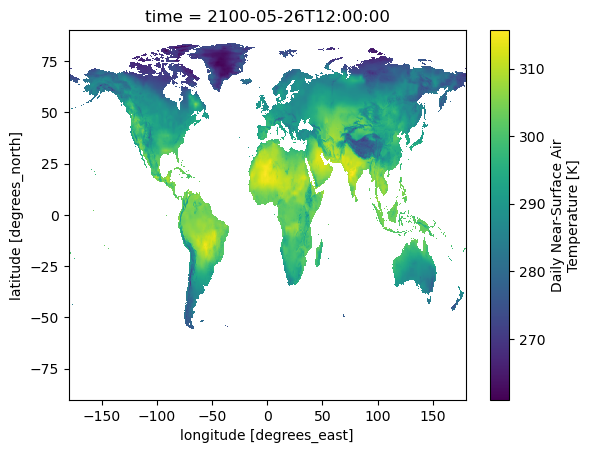

In [15]:
ds_model.tas.sel(time="2100-05-26").plot()